**Historical evaluation.** These checkpoint results use the original off-route rule. Use NEAT_Speed_PID_Comparison.ipynb and NEAT_Speed_Results.md for the corrected comparison.

# NEAT speed checkpoints

Reproduce figures 1–3 from the speed report. The compressed cell carries the matched per-episode data, generation history, and frozen selection metadata. Run all cells with Python 3, NumPy, and Matplotlib in Jupyter. The embedded results need no simulator, checkpoint files, or repository.

The 0.50 and 1.50 m/s columns measure speed transfer. Each intermediate checkpoint also ran at its own training cap. The six phase winners were selected from validation before the supplemental replays.

In [1]:
import base64
from collections import Counter
import gzip
from io import BytesIO
import json
from pathlib import Path
from statistics import mean

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
import numpy as np

EXPORT_DIR = None  # Set to a Path to also save PNG and SVG files.
BG, INK, MUTED, GRID = "#f6f5f0", "#17262c", "#4c6168", "#d7dfdd"
TEAL, BLUE, CLAY, OCHRE = "#087f72", "#416994", "#ba533c", "#a87516"
PARENT, EARLY, FINAL = "g94-parent", "speed-g00", "speed-g98"
PLAIN, FILTERED = "pid-plain", "pid-filtered"
COMPARATORS = (PARENT, EARLY, FINAL, PLAIN, FILTERED)
TRACE_POLICIES = (PARENT, FINAL, PLAIN, FILTERED)
LABELS = {PARENT: "NEAT g94 (parent)", EARLY: "NEAT g00", FINAL: "NEAT g98",
          PLAIN: "Plain PID", FILTERED: "Filtered PID + recovery"}
COLORS = dict(zip(COMPARATORS, (BLUE, "#795e92", TEAL, CLAY, OCHRE)))
DIFFICULTIES = ("beginner", "intermediate", "advanced")
CAPS = (.50, .65, .80, 1.00, 1.25, 1.50)

plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "font.family": "DejaVu Sans", "font.size": 11, "text.color": INK,
    "axes.labelcolor": INK, "axes.titlecolor": INK, "axes.titlesize": 13,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": GRID, "svg.hashsalt": "neat-speed-results"
})

def page(number, title, subtitle, footer, height=5.4):
    fig = plt.figure(figsize=(12, height))
    fig.text(.06, .96, f"SPEED STUDY  /  {number:02d}", va="top", color=TEAL, weight="bold", fontsize=10)
    fig.text(.06, .902, title, va="top", size=22, weight="bold")
    fig.text(.06, .824, subtitle, va="top", color=MUTED, size=11)
    fig.text(.06, .041, footer, va="bottom", color=MUTED, size=9)
    return fig

def save(fig, name):
    png = BytesIO()
    fig.savefig(png, format="png", dpi=160)
    if EXPORT_DIR is not None:
        path = Path(EXPORT_DIR)
        path.mkdir(parents=True, exist_ok=True)
        (path / f"{name}.png").write_bytes(png.getvalue())
        fig.savefig(path / f"{name}.svg", metadata={"Date": None})
    display({"image/png": base64.b64encode(png.getvalue()).decode("ascii"), "text/plain": name},
            raw=True, metadata={"image/png": {"width": 1000}})
    plt.close(fig)

def label(policy):
    return LABELS.get(policy, f"NEAT {policy.removeprefix('speed-')}")

def show_table(headers, rows):
    lines = [headers, ["---"]*len(headers), *rows]
    markdown = "\n".join("| " + " | ".join(row) + " |" for row in lines)
    display({"text/markdown": markdown, "text/plain": markdown}, raw=True, metadata={})

In [2]:
payload = (
    '...'
    'vw6P3543/+EP//h/QfYR1q0vCAA='
)
data = json.loads(gzip.decompress(base64.b64decode(payload)))

In [3]:
def group_episodes(records, tracks):
    grouped = {}
    for r in records:
        group = grouped.setdefault((r["policy"], r["cap"]), {})
        assert r["slot"] not in group and not r["error"]
        group[r["slot"]] = r
    for group in grouped.values():
        assert set(group) == set(range(90))
        assert [group[i]["hash"] for i in range(90)] == tracks
        assert Counter(r["difficulty"] for r in group.values()) == dict.fromkeys(DIFFICULTIES, 30)
    return grouped

def describe(group):
    rows = list(group.values())
    finished = [r for r in rows if r["done"]]
    reasons = Counter(r["termination"] for r in rows)
    return {"n": len(rows), "finished": len(finished), "failure_pct": 100*(1-len(finished)/len(rows)),
            **{d: sum(r["difficulty"] == d for r in finished) for d in DIFFICULTIES},
            "rmse_mm": mean(r["rmse"] for r in rows)*1000, "mae_mm": mean(r["mae"] for r in rows)*1000,
            "progress_pct": mean(r["progress"] for r in rows)*100,
            "observed_forward_m_s": mean(r["forward"] for r in rows),
            "finished_time_s": mean(r["elapsed"] for r in finished) if finished else None,
            "off_route": reasons["off_route"], "stalled": reasons["stalled"],
            "other_failures": len(rows)-len(finished)-reasons["off_route"]-reasons["stalled"]}

def pair(first, second):
    assert first.keys() == second.keys()
    rows = [(a, second[i]) for i, a in first.items()]
    shared = [(a, b) for a, b in rows if a["done"] and b["done"]]
    result = {"both_finished": len(shared),
              "first_only": sum(a["done"] and not b["done"] for a, b in rows),
              "second_only": sum(b["done"] and not a["done"] for a, b in rows),
              "neither": sum(not a["done"] and not b["done"] for a, b in rows)}
    for i, side in enumerate(("first", "second")):
        result[f"{side}_rmse_mm"] = mean(p[i]["rmse"] for p in shared)*1000 if shared else None
        result[f"{side}_time_s"] = mean(p[i]["elapsed"] for p in shared) if shared else None
    return result

groups = group_episodes(data['episodes'], data['tracks'])

## Validation through the curriculum

Diamonds identify the phase winner. The teal line accumulates the best completion count within each phase.

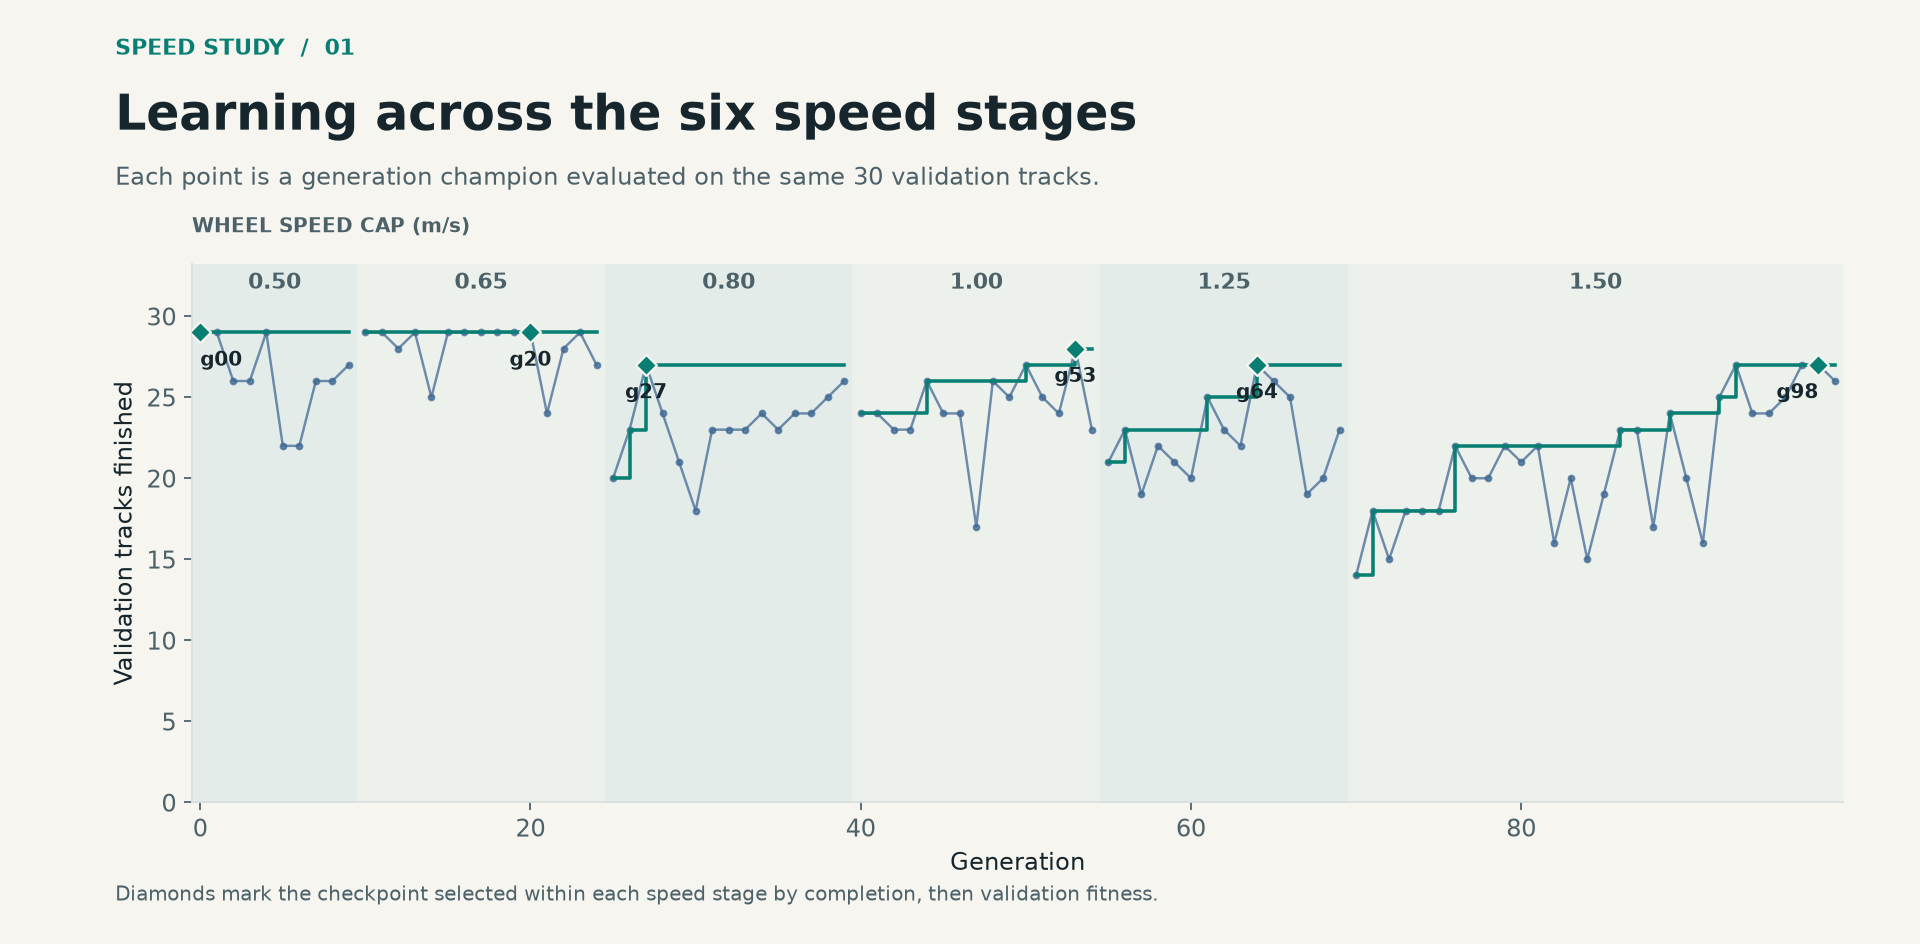

In [4]:
def learning_plot(generations, choices):
    fig = page(1, "Learning across the six speed stages",
               "Each point is a generation champion evaluated on the same 30 validation tracks.",
               "Diamonds mark the checkpoint selected within each speed stage by completion, then validation fitness.", 5.9)
    ax = fig.add_gridspec(1, 1, left=.10, right=.96, bottom=.15, top=.72).subplots()
    colors = ["#e4ecea", "#edf1ec", "#e4ecea", "#edf1ec", "#e4ecea", "#edf1ec"]
    for cap, color in zip(CAPS, colors):
        phase = [(g, n) for g, c, n in generations if c == cap]
        x, y = np.array(phase).T
        ax.axvspan(x[0]-.5, x[-1]+.5, color=color, lw=0)
        ax.plot(x, y, ".-", color=BLUE, lw=1.1, ms=5, alpha=.75)
        ax.step(x, np.maximum.accumulate(y), where="post", color=TEAL, lw=1.6)
        ax.text(x.mean(), 31.7, f"{cap:.2f}", color=MUTED, ha="center", fontsize=10, weight="bold")
    for row in choices.values():
        gen, n = row["generation"], round(row["validation_completion"]*30)
        ax.scatter(gen, n, marker="D", s=45, color=TEAL, edgecolor=BG, zorder=4)
        align = "left" if gen == 0 else "right" if gen > 90 else "center"
        ax.annotate(f"g{gen:02d}", (gen, n), xytext=(0, -15), textcoords="offset points",
                    ha=align, color=INK, fontsize=9, weight="bold")
    ax.set(xlim=(-.5, 99.5), ylim=(0, 33.2), xlabel="Generation", ylabel="Validation tracks finished",
           yticks=range(0, 31, 5))
    ax.set_axisbelow(True)
    ax.grid(axis="y")
    fig.text(.10, .754, "WHEEL SPEED CAP (m/s)", color=MUTED, weight="bold", fontsize=9)
    save(fig, "01-speed-curriculum")

learning_plot(data['generations'], data['choices'])

## Completion and tracking at matched caps

Compare each checkpoint in the 1.50 m/s column to hold the cap and tracks constant. Mean lateral RMSE includes each episode through its own termination.

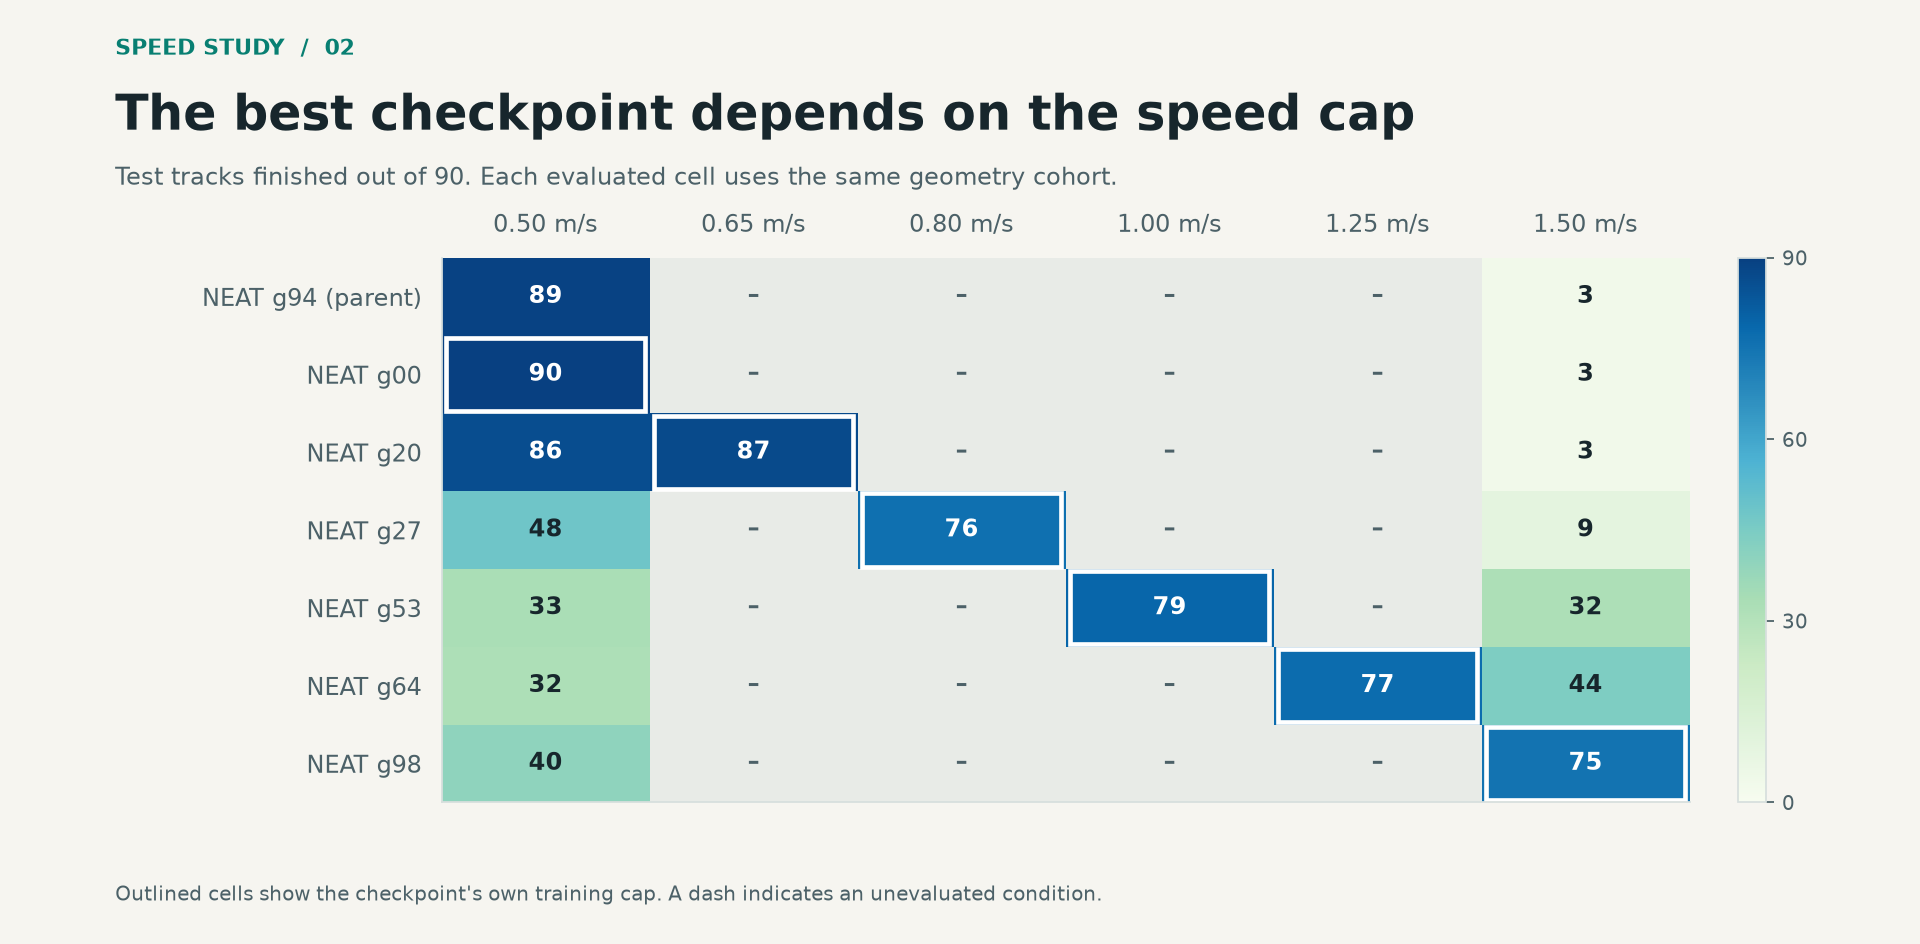

In [5]:
def transfer_plot(groups, choices):
    policies = [PARENT, *choices]
    matrix = np.array([[describe(groups[p, c])["finished"] if (p, c) in groups else np.nan
                        for c in CAPS] for p in policies])
    fig = page(2, "The best checkpoint depends on the speed cap",
               "Test tracks finished out of 90. Each evaluated cell uses the same geometry cohort.",
               "Outlined cells show the checkpoint's own training cap. A dash indicates an unevaluated condition.", 5.9)
    ax = fig.add_gridspec(1, 1, left=.23, right=.88, bottom=.15, top=.727).subplots()
    cmap = plt.get_cmap("GnBu").with_extremes(bad="#e8ebe7")
    mesh = ax.imshow(matrix, cmap=cmap, vmin=0, vmax=90, aspect="auto")
    ax.xaxis.tick_top()
    ax.set(xticks=range(6), xticklabels=[f"{c:.2f} m/s" for c in CAPS],
           yticks=range(len(policies)), yticklabels=[label(p) for p in policies])
    ax.tick_params(length=0, pad=9)
    for i, p in enumerate(policies):
        for j, cap in enumerate(CAPS):
            n = matrix[i, j]
            ax.text(j, i, "–" if np.isnan(n) else f"{n:.0f}", ha="center", va="center",
                    color="white" if n >= 65 else INK if np.isfinite(n) else MUTED, weight="bold")
            if p in choices and cap == choices[p]["training_cap_m_s"]:
                ax.add_patch(plt.Rectangle((j-.48, i-.47), .96, .94, fill=False, lw=2.1,
                                           edgecolor="white" if n >= 65 else TEAL))
    cbar = fig.colorbar(mesh, cax=fig.add_axes([.905, .15, .015, .577]), ticks=[0, 30, 60, 90])
    cbar.ax.tick_params(labelsize=9)
    save(fig, "02-speed-transfer")

transfer_plot(groups, data['choices'])

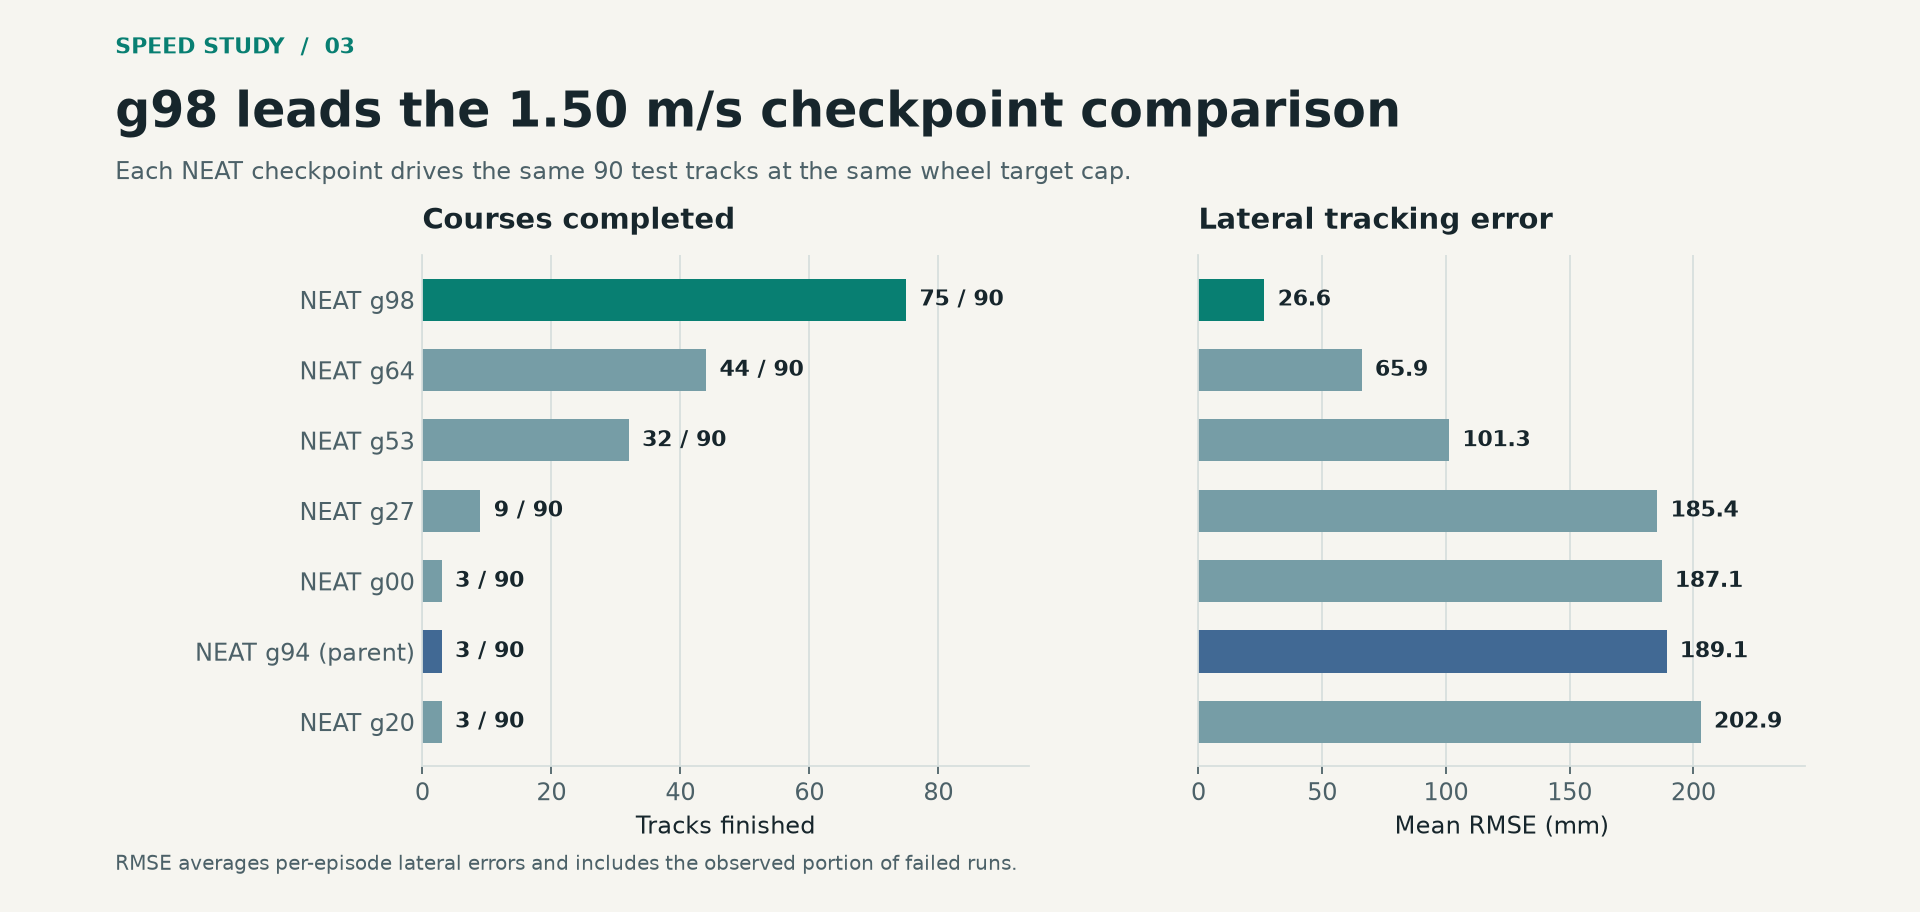

In [6]:
def ranking_plot(groups, choices):
    rank = [(p, describe(groups[p, 1.5])) for p in [PARENT, *choices]]
    rank.sort(key=lambda item: (-item[1]["finished"], item[1]["rmse_mm"]))
    fig = page(3, "g98 leads the 1.50 m/s checkpoint comparison",
               "Each NEAT checkpoint drives the same 90 test tracks at the same wheel target cap.",
               "RMSE averages per-episode lateral errors and includes the observed portion of failed runs.", 5.7)
    left, right = fig.add_gridspec(1, 2, left=.22, right=.94, bottom=.16, top=.72,
                                  wspace=.28, width_ratios=[1, 1]).subplots()
    colors = [TEAL if p == FINAL else BLUE if p == PARENT else "#769da6" for p, _ in rank]
    for ax, key, title, xlabel, xlim, fmt in (
            (left, "finished", "Courses completed", "Tracks finished", 94, "{:d} / 90"),
            (right, "rmse_mm", "Lateral tracking error", "Mean RMSE (mm)", 245, "{:.1f}")):
        values = [r[key] for _, r in rank]
        ax.barh(range(len(rank)), values, color=colors, height=.6)
        for i, value in enumerate(values):
            ax.text(value+xlim*.022, i, fmt.format(value), va="center", color=INK, weight="bold", fontsize=10)
        ax.set(yticks=range(len(rank)), yticklabels=[label(p) if ax is left else "" for p, _ in rank],
               xlim=(0, xlim), xlabel=xlabel)
        ax.set_title(title, loc="left", pad=12)
        ax.invert_yaxis()
        ax.tick_params(axis="y", length=0)
        ax.set_axisbelow(True)
        ax.grid(axis="x")
    save(fig, "03-fast-checkpoint-ranking")

ranking_plot(groups, data['choices'])

In [7]:
rank = [(label(p), describe(group)) for (p, cap), group in groups.items() if cap == 1.50]
rank.sort(key=lambda item: (-item[1]["finished"], item[1]["rmse_mm"]))
show_table(["Checkpoint", "Finished", "Failure rate", "Mean RMSE (mm)", "Mean MAE (mm)"],
           [[name, f"{r['finished']}/{r['n']}", f"{r['failure_pct']:.1f}%", f"{r['rmse_mm']:.2f}",
             f"{r['mae_mm']:.2f}"] for name, r in rank])

| Checkpoint | Finished | Failure rate | Mean RMSE (mm) | Mean MAE (mm) |
| --- | --- | --- | --- | --- |
| NEAT g98 | 75/90 | 16.7% | 26.65 | 14.57 |
| NEAT g64 | 44/90 | 51.1% | 65.92 | 33.30 |
| NEAT g53 | 32/90 | 64.4% | 101.27 | 60.96 |
| NEAT g27 | 9/90 | 90.0% | 185.36 | 130.10 |
| NEAT g00 | 3/90 | 96.7% | 187.12 | 136.91 |
| NEAT g94 (parent) | 3/90 | 96.7% | 189.12 | 139.87 |
| NEAT g20 | 3/90 | 96.7% | 202.93 | 147.53 |

## Native-cap tradeoff on shared finishes

Pair g98 at 1.50 m/s with g00 at 0.50 m/s to compare actual completion times. The two controllers run at different wheel target caps.

In [8]:
r = pair(groups[FINAL, 1.50], groups[EARLY, .50])
show_table(["Shared finishes", "Mean time (s), g98 / g00", "Mean RMSE (mm), g98 / g00"],
           [[str(r['both_finished']), f"{r['first_time_s']:.2f} / {r['second_time_s']:.2f}",
             f"{r['first_rmse_mm']:.2f} / {r['second_rmse_mm']:.2f}"]])

| Shared finishes | Mean time (s), g98 / g00 | Mean RMSE (mm), g98 / g00 |
| --- | --- | --- |
| 75 | 6.54 / 8.68 | 5.74 / 4.31 |